# Clase 12: decisiones con Monte Carlo

Estudiante · Investigación Operativa · Universidad Austral

Hilo: datos → calibración → escenarios → costo → comparación → cola → selección → holdout → estrés → recomendación → Markov.

El histórico es **sintético didáctico**. Todas las cifras monetarias se expresan en UM por ventana, excepto los totales de 30 ventanas.

**Andamiaje ejecutable:** las funciones `costo_propio` y `cola_propia`, y la recomendación, quedan pendientes. Los bloques posteriores usan el modelo de referencia, claramente identificado, para que puedas inspeccionar el recorrido. Ejecutar sin errores no acredita completar estas tareas. Sustituí las llamadas de referencia por tu código una vez que apruebe las pruebas.

## Conceptos antes de ejecutar

Una ventana es **un día de operación**. Régimen alto o pico significa un tipo de día con demanda media 140, no una demanda que supere 140 ni un incumplimiento. Al reservar no conocemos el régimen del próximo día. **Calibrar** estima parámetros con el histórico. **Media** es promedio, **desvío** mide dispersión diaria y **error estándar** precisión del promedio estimado. **VaR95** es el percentil 95 del costo, **CVaR95** el promedio de la peor masa del 5%; ese 95% no es confianza estadística. **Holdout** es una muestra reservada para evaluar después de congelar la decisión. **Estrés** evalúa una política fija bajo supuestos adversos. **Markov** modela el próximo régimen a partir del actual.

## Datos y funciones incluidos — versión autónoma

Este `.ipynb` puede copiarse solo a una carpeta vacía o subirse a Colab/Jupyter. **Ejecutar todas las celdas desde el principio**, con Python y `numpy`, `pandas`, `scipy`, `matplotlib` instalados. La primera celda contiene los archivos originales comprimidos, comprueba su integridad y los prepara en una carpeta temporal nueva. No descarga datos, no depende de rutas absolutas ni modifica archivos del usuario.

El histórico `historico_200.csv` contiene **200 ventanas: 170 ordinarias y 30 altas**. Sus columnas son `ventana`, `regimen`, `demanda` y `origen`. `results/holdout.csv` es una **tabla de referencia**, no un segundo histórico: el notebook genera y evalúa un holdout independiente antes de contrastarla.

Todos los históricos son **sintéticos didácticos**. El inventario aparece al ejecutar la primera celda; sus bytes y los módulos de referencia también pueden consultarse en el ZIP. Los pendientes de implementación del estudiante se conservan como ejercicios; no son faltantes de datos.

Para acceder a un CSV completo después del inicio: `pd.read_csv(ROOT / "data" / "historico_200.csv")`. La compresión permite incluir todos los registros sin pegar más de mil filas en el área de trabajo.

In [1]:
# INICIO RECURSOS AUTOCONTENIDOS IO 2026-10-26
from pathlib import Path
import base64, hashlib, io, zipfile, tempfile, sys, importlib, importlib.util
_IO_MANIFEST = {'scripts/modelo.py': '67470549ee32d5115a1acb74af13391aac79a727987ac67d64acd3bf7d8033a4', 'data/historico_200.csv': '100a89b0a8a6a74ad9b59927cc8c1d4e4be5eac2d4ce6b5ce5756371553731dd', 'results/estres.csv': '4bb9a199703711e26eee8a6bee22dfe0361a54ceae1237f16c9b3509d0e791a5', 'results/estres_base.csv': 'cbde7832cfce84438cedd74ac69a09ab45f147ad244af90cd3c2581481ed5521', 'results/estres_buffer_10.csv': 'f37ae6ff837d8582756436fb36fca48e664c1dac07b06892d74eb8ea6d51fdbd', 'results/estres_penalidad_350.csv': 'e0e6f884da24a4b6cedda710f1edfcbbb9d60d5d0c691a8453e0faa7f02690f4', 'results/estres_pico_25.csv': 'be7b7988162925eb9d3e7c5814b16cec1b16b50aad0395fa948cede2b6dabbb2', 'results/estres_pico_intenso.csv': 'bac24788c4f337cc8361f94298e02a2bf49d3b7cd59cbb8a7e1929bba306fbce', 'results/holdout.csv': 'ad278d546545afa0c73a7462720109269e3a38b52733c7de280f8405ae602c1b', 'results/markov.csv': '9525e30f042fa3a1e22703343e221c16fb115fb2c4577717f9f4b8fbae50725f', 'results/matriz_ejemplo.csv': '8fc74ba13b94d85e877747f53dc5ab3ee4eab6b80fe00986b82d176cba26cd90', 'results/pareadas.csv': 'fe4095c1fee84bd11012275020896e7571b24c653c87abacb9a75ae69427718d', 'results/seleccion.csv': '1b4b9cf36b34e5edd2a84c2598cfb76f775b2a8d31421dea20e19575d112bbea', 'results/sensibilidad.csv': '1f1a9bfdea5a89d220c1ce42c1bf8001a6baa0852446a56b0e8a7d675aab34ac', 'results/configuracion.json': '3da150938eb3064cee326b8fe9f4698b5665047d02df9ad4ff4065def3f47150', 'results/politicas_congeladas.json': '1fe48721fb1ca089edea34b45116b0f020a99542b09e753ea862d27c05dacc9b', 'results/calibracion.json': 'afc22dc49815eacfbc0337ae955c23eaab31be7ac834c9906a82bcf3bf5886c5'}
_IO_ARCHIVO_B64 = 'UEsDBBQAAAAIAAAAWl3KOiNdvwkAACYxAAAWAAAAZGF0YS9oaXN0b3JpY29fMjAwLmNzdpVa2apYRw58n2+5HLQvXzOY2ATDxIbEzPdPqftc5tXyxXECkU8vpVKV1P/99uPXlx9fPv7+9uf3v779+Pj67a8vP75++fj59/c/v/34F3/QR9vjZNxZml388c/3H7++/fr+x89/f/3+9csf59/++ongXz//+fcfP3/8+vvnf758/fnPvwTBZQ8rqWSad8vvByuCmfTpjspO69JFtM266WlO5WgsIBfr9ll3PtqiZeEsEb8fHPNlR3Bqe6dn9O8H5wTrwyKlzBFNiz3XLDsejVJq4WCp3w/u+TLjyyne2LKw/n4w07ksfiRaosqUaLFrHpRFPZYmXsVkuomW83F/mCLZmtJqsXEeoBWi2VXMsPrafNxudFlqILZbbRHtH/zBhmPHReOHOX0BNY732IE1Iwkr2aQn58W5OE68nBjbX0QP3DKQYsC5pFn3JrrfSzP3cMHGY0MOcgFnj6lVuFW7LvAqfOkhqfHl9gBFLaIHcFmPAKbgJtLwTfQn3kJdkWzOvECr2KUXnBcN4CxkQ8gHbyEPhSaWrty6+fjgrfjxwKWTF8Cai+h8Gd0TfByT6htSlsFb16OGYycTUl/kqVy80RMJsJa6iSzgqnSJmQJ4FQ2Q3GLnyrcQUin4hZNrs3Q9cBt6y4NXcPuCI5AWuHIFuUa4Nge5+yL84K0fmZJkiqK0wbpOJe142AhIL2qLRZbqgVs/gCqrDrf6JjrvtwUYD8DOzBdo07r7xoEP3IhWxVT7Zil2LBJawZuKZAO21Eca4Y3dI90W0XzzBMkNZgY7Qv4soo9mmzQRJdY03vCqHdHG9LhRQfCRdS7ggvIDrArWDuFj4BivTTk0v2KVVKEBoGF8pRiPcJNHCreGUoiyvLmzvNQIwQi4gCFsI4CsDjtNMR0VkCjmvll6X+VXBaXag5lapLgfbkvcmeRRILkBq/MVjipCgVpOtJEgLvfQARMoEOX5WURfbsPGIXe9hYC6BV7cLr9AuaEkFPxJbI7t1FJ1yIBO0CobJPciPO65eVgiR6HicvPxvALGkCZm6dUbAeMHboKP92jOdgI9L8JvLa2HoCGEGodui2oYNAfHABzwgn2D5TZbj1NM9SlYlARD4NuLtYdcdgRSRy8rcn3zbX1VK43SFvHdrYVdHSCR+LoiUzcmK44txalDNyl0b1duTn3wlvJA+jQFZAx+L6IHbwkZgEyDhsHFr/b9WoWAYsVlE6rh5sr6pinELswdW9hGsybdfeeQqk1Bpk00H6wOMUvAJymvHFbKe2XZkRB+EBKLC0+9SV7lnvi2U26i7VIrNg6TkKimvGlE+BW8KfhVUH9tiyvLAzZ7GDrAO1MhJBbReZjVHhcL9oL2kwXSs+6NQ+x6KE58JZ+yrwAqoCUhOsExC7wUXXOXsNLNDaG/IafimyeO7FQIbV/tu+T1xICqG9Tf8PIi/BRT02dw3pZwKRvJW3YZwlxqwNa9kZ3l79oF3rAd5jZ6s/W4eZZTSiFbizYFqfK1Z6ji4HQIGV6QWx245UMwVuwCwG5KcfXb8VO2cTi50ttNd+UIRqIC57XJ0j5wI4CVioZcaNO7ajnUyMgUUihOuEte5Fnr1aznwofToWQW0ccpgGH0NH9gy3vjS/v23WDQshAPfoLNW4THCQ/IAHhxmVvbdIj74E0eR0EAMeL7q7XXxXoEUhTezr02S7/aDexYPS19FMVNLWY64k3pwZEJw1PvekCQe7cqMfghh6ZgtDbhcrVARYLdGhe3SRcmvWcHwAUkFBYQq6/ba629UZPh10JXez+o837a4Q8tSXPVMqWX5RgiBMcGj7sRgPj/L9XAMAA7UI+rHhaqyb05rL0h2eGRN00spv6c55RGVcpMVjYjArrmHn4DUgomE3/LJpxfi5yacDzDV6sBhVzT4YM7pE3OaS7C9W3UJywDwSTbqu/K/DpVMlSJafP3Cnjsn93LKLAenKotCIfPmAGbF2QrXItFr7KGX9xB1cxYaroyq/B6j57ANhCTAP3q5vrtEXCNhiaH/9kk3Zk0IOehRxX3prKS8HwmDUeUFahONVA2Nmd/Zg3ND4qcTh9SVq0dvsMGexJ0oRSc2MEm/JRZw+5NSKbzbavhmLyT1EC1wQY8eyNoWd4eSeHsQiglfXV1+da6IJRaMAb8/urw6vovhv2CpoVt3ehCPiOHRKGmHuyg1PRqLEnXQ0lj4wIvsFLErPxp/+CeVDRz01FklTdtwDYk0MVlG988KvZ2SubaIzwB+w3u9S21PZYdpI0/V8v3VxgjGArTXFc3r/F6IRw7asXE2yo+32kTKGM8MOh+M8hnfWddTYbonIb06vD67r4S0h7eP3Qz+uA7f4DMQdphAWK+6ZGxvR1hlBp8mMCgq1p3JhAxe58W3QxYN9qazwgCOgGFWuVI3I2yh6KdvfMpVvBiNIPGTbhfaQ95Q9wCvtmYQT4ziOhHJO3QPZTKJvwd6DfcUAUMoW0GIHymELi4AGrgisCWK9CfKcSoY5RsBXSgcldPIej1ZDmWBspYdjLjDCKm1wayLx9pbxvcnEkEbm6e3QzZkm66+TD9V18SxRS5mVWuwu2i1ucxAhEMxqb3ggJ1543RBKIzTl4Vys9ZBAnDz5mg0G1gd4YRNe1dG3Eezitt7W8DJaYXP8Cv1esf//9LksapTbtv9fYo6PM9xlgqDlizVTjfcMhqyBSTqBXbxa2zk/IAfEFird7BYLmnCzONWoI1yuCdto+3S6wFT6WgLV2xbXz27QK2IOcRjm96jhzvi5JGvsEdHHeyCc97+GAMQ8rbzAE34XV7lq0y479557chvPjspRTB0SoOP1bW5Iwmaq4+ZrCBC1xdXb6DfkGRA1XWeItNuNxmM2Knv66cubn5PMCLMZXTusP592b2yvlaWpmVu+HuNi3bGbtNtaAHXjih1Ic0V58/Ck9R7Gxa3WBtk40zyrzL5xmdolaJbwZinO9bTeSf80waciUz7pAiZzqTgv9qXnmDzylFxbxNQbmzlTOpF3jw8TN8Ralevbe8cwqefgL+iWvD6a/eHU6pjXg0HaQBrc0rZ3IGFdCXLuchWM2MaBPu97UEil1altPqERvX55NNmXxTAnHJBjj16Wnx6Vk7NPIq7XBT94kNuHq4XlhW1uLMK07fHTJrZpq6eUbH/ZraaIclx/ZXw3vut9hGnddJTrEq9S1XZeHD0w+BL9s88eEzskCtrHkjg5ugnbG5M4vwKTeaoE3kz2r1/gkdnLw7fL36JuvfqQWkCko1hEb56sEK91tsz6iJbJqwG+SeuUUrhFIJrq+mr7EJv3284bxoSM6k6Y39drwQvSNCFoc/0rbN0OV/UEsDBBQAAAAIAAAAWl1VatGwaQAAAMoAAAAYAAAAcmVzdWx0cy9jYWxpYnJhY2lvbi5qc29uq+ZSUFAqULJSMNAzNNUBcXJLDYBcSwM9A2RgCJYrTgHL6VmiAGOoPkOgnKEJmkZjqEaIJJpOsJwTUMbIVM8AzClKLU4tKksEKbaACqXmJBaXZCaDxExhygpS8xJzMlMSU8B6gVZy1QIAUEsDBBQAAAAIAAAAWl0ksuOarwAAAG4BAAAaAAAAcmVzdWx0cy9jb25maWd1cmFjaW9uLmpzb25djcsOgyAQRfd+hWHdEMD6qN/RfUORRBIUIrgwxn/vKLSQspp7zjB3L8oSOSkHh/pyhwBxVM6bRXEgjLCGEkZuwTippRDKzEk1UY1GD2b1SbRRSOcX6RLvIvcL36S4ijL7AHmcG2h+5W01gRd5qsrpryeHfyX11zwhVGG0mx+vClRhyjC9o/B3nex2UoYrXAdm+TxcdwACDtAJFRYppi0mAU7cW228Vu94mOAOFccHUEsDBBQAAAAIAAAAWl0I2/vFDgUAAOcKAAASAAAAcmVzdWx0cy9lc3RyZXMuY3N2rZbNblw3DIX3fZYLQRRFkVz3DbrI1nCdSTGAM3biBH39ftQ4qO140yIby1ejn8PDw0N9OT6fPp5vj6fTcb67OV8+1fD0/fE4X+6+f368P38+ny7fHo6/z/dPD5e94PnfWvTh9o+04/frcHf79HB8ufl6ejrdn+7uzqzh5L8uD0/fzne3v8norR9jajQLWSpuqmMdsy2NZdF7H7pEhDUj24yMNbqPWMrM9LZcZ5ep6hF2cJhNHXtknyvL54rMeZ1bOqV72Fw+x1yHhmlLLljT1+wrjsVH21dM1srI489baJBhYLWNdUbTpTm8i+VSPRTsMVI8gW4WqxZJU+3hJl1kDWfKrGmu9Ejt3FaA1HUPVnjMep+rxxg7EAX2CvVhOsIMsBOyZFnaGjM65NrIaMOnx3RdFdC/YOcm1tybqXsvioeLHdK4aUFLdkvmi0jz2RwObaWsCoup6AQw+vS0jCkbUnfZA1T1JAQiEfat5x8DJISfnDS9z4Ms2WvAagm7umBLSTRRv6R3I4arFgvesndzdh/WYs4xuGAk25KDSVibMgh7rUEoxEBGmo7BNp0BIQUphVwwRm1bAo9zrbA9l5ypPVdHctZNDpuV38WddcSUAymir6LKutuYeTye7x5uyI5o/6EGi1HKBayKOjqdzYbrkMFnWI9NrzbnP47RuXIwAw3oYc4MdDRyI0JK11GKfZeIdOtz7lDQ1chOhWgCPbkHqb2EK0jXX+O114CviijqdGjJuyO5RBDRQ5SNiNiHStai0dxzpM1EuG41lZUXSVEZa/Wd85L2HoHr0yaMmfFnzxGlWxCUroQJOWClt5A5IYzKKIlQENKq2sZAT0PN35C8McfMNsITRigycitVH5S3lNC4JEps+MOiIsHsjtK3/qIh3wwOjmG7rqSPfhUAOq26ADdxdt2/8QWVVUyEScaDWFvKDAzHwAldwpVt4iiZJJkMXhGfL99OF7wOmn9ogyQ2hzIbFDBZWkdgLZgZ0istb1vwhBNcYeF1AR1WkWB/ZJHCKsPaNRcg2aOtSrFiN9TUuEaCdCCvV00vDj9WrreokecL1PYO5qs83INlqMDLzqg1IhHAYacwD2TUwWdDeMu2QepE4rgvqiLPEGqY6lZHRbBH0oq34mPUQ7+qYzqlKkxOqRgDK+7WqF/sLJOcYA0rplFci8wjENzmPaavog7sliR2OM/S4kElAAYpxtwGYSVhWFGAkN/k8lGukRhJKLU2cB4tqkX6VSdQgX+MYgwfHvsnhaAMrWKH63Gs4utVA0lU97KB4MnfP306fb2R/lIbZKztDCIPp+qOhZGXc3akgUbpTOWFSr24KEHMupApug8dzgSfBejmmbYzrjpAz1gGnE4B2J4zLzrhAqnifLbkDeAt8ReA/S3gZ99QvFzwS+rH6QdIt5VjcJcLAteQAkyPtuq5SAhbKby9OYkwxbQIy/5z2/u5i1Ck+rLtxU8UXx8VScMlesOayjqrk0DHHDvfDl1omeTjzbgqAsMQcWJE6vVUMLgwGp3+j2dFokc6/0JtKCxNDyCMhtxIA8LCjY7H0+X2/vzx9uMNjeHVA4OWoj4XOOiteG71lFn+l2UUcIM0iLxhRPgw548dCT2FOuQ2E55Sc/2KB0aWHdCjjF6AuvI91M8vDVB3oVs45wfWSmOpyDslhLAomrI24zwYwQCrAil79pElLqZr0tFWzl/z0ChHGFQnFs+DjV78DvJ/AFBLAwQUAAAACAAAAFpdnZyRUJ8DAABFBwAAFwAAAHJlc3VsdHMvZXN0cmVzX2Jhc2UuY3N2ZZXJjls5DEX3/hZB4Dys+w960dsgSCqAgRrSqA7y+30pe2PHgKEqmU86vLzk+3e9vXy/fl2fL+v67cv1/ccsn79+ruv7t19vP1+vb9eX9/8+1u/r6+fH+wm4/zlB/3z9u339dZYLEy0J5V0d3a4aFamLaYuFVVeEpjFiGDGslc5dmYYd591FzG5pHZSLNovpWdg0Oj3Li0Lt7KUIIVJEtEJWWetuDQ7LMIpeDBregSgcY8wyfL7EDbvuQsYVJaCvHWWeUoErKFkQJLZD1Yxxc3VjxxGW0ZFEmt4HcA7EQpmFw0S6OUrl/KSS2aWkrE0gTNUHwlpd9gAYFxy4xEp2kBU3CNmBkxtBygypGleIIihqW5YVZEzJ2enYE+RIvmnyok2tImelJEknJG8M2rPnOA0SQnVrjxWcT4DQ5w9AKGjWW/G0m5clvst3Oc4zUJK7EkpsmrslqyyIPYeYdoWGmEc2+IcBohy+ZIosRHOgsmRnz+EWhFIjGUHZnfgJMF0eAOvCMgpqbcdRygkTSqwpJqpbRCR4nodPeh9LztPgmrQSFVaDHKpAOQK63QABgN8QDvBuu+3Bi6h9uUUa8lta/gSIfB8AG4BHwdoaCn2gTcNoSwEMM3KiYnBnxQTxVqVpEvQFdMGWO5RHL1Qr4Yqh0NSz+EC4E0HoEjn0ClYYMsVVylFjNYE3w1Fv+AwlWy5dW3K8lFMc1FhHwoyNJmCqnnot2UkmEEVwAUwtE8Ib3ZeENoG8PsjwS4GSDR/44ZAh9TirEvLm+Y7zjoTiCbuDJwQDIrWWivojobnILngrIGTA3mhknUZGKnAZF6ENAo+tGSFoabio8eUpiTgjERS7pxThEbfmVrRlwBzufXMb32rKyhOKO5vAGoecfXoHfYWiTqvngs2fdNTO3MrjOjEaMS9sENKx7Zo5MpQkDyXqhMloTRgjJOM9yLATtvPABBlTYKsIlOiFbJ9JcQqKRjkLQKhzZio8Dn3vPxbqCPM0TjLUa81Ie8L0hiF1Bp/OgE4DJm4LMzgXBzsXhqrNgX0+IGz0TcoEycb/CEokYnS2AtN+gAL6wKwHRK1uKx50zEDMEcykux/IYNbEnID1MXAxSSXqWU0IPONWDZJGGwHToWaOfWFo2Jnxljgun2sb4xbJO2yF3oYn9kx2vC9QupipnxgUKENhJIs23HlIWO/rTC3AwNcwWfB9F4UQ4Xk5DPPoieQ3LWVS0BnshB4m68v/UEsDBBQAAAAIAAAAWl0pmR9AjwMAADUHAAAcAAAAcmVzdWx0cy9lc3RyZXNfYnVmZmVyXzEwLmNzdl2VTY4dNwyE93MWQaBI8W+dG2SRbWA4DjCAPXbgGLl+Pul54TcDDNRgq8lisYrvn/Hl01+vH8b3T+P145+vb3+f4/uPb+P17eOPL98+v355/fT279fx3+vn71/f7oWfj+fSHx9+bx+/3eNliQyTvWfl8mXmay33sfbUkFiZolleyaUVs1UIhFtwxyR1lqrpll2eMWSusH0PWXVSaSyPsBu6f+SM8Ko11tqrZhuBnbEleixrjRkU0W2br4HnQ3v1LLFqbd++O8bS6cZzlsjuvaKGVvtU29YUdKeANm1ZmrWQzlddGNsfB7jL3F2WW/YjVmTiDXXWFt9jifp7iJrxBNFe1hKqqwGpvEWS2xuMMmsXqVXETVQORtGpudvdukIgUetwL6q6k6/qsmf+YNHUonn2bbll5Y2VRdCzCl226mjp9xih/wkjY16UogAYdxok0GaNnqoVUXzpQq7kDgMAh2+BNRO4pmElGazQCKzcMZP4HmuDMP1IRH6OnhRU3lyH4dABA0/4Cmao8A6fwmHUmoxPBJ4aGnPkjC7Yy9pK03YIQ0TTSLPSEAYDINSALluFGkNtHRhHORySWasO/EYlpveVaWaXiSE4AWJw6Rliw8uvCAOEp7bF6b0Us2RSOhhnb2O8qagFAYyDYIKOSW2+pgChXXOb+vLqdcYuUxCG3vNYCv59YwiA3JhnNxyWLMQSw2O9A1jr2Sn5suxQiDOSwqaYrxDC2LMxSB2tkC3zoEGFTXIt2916EOMnTTGMbhwHAr658HJJZCWODXqUfWMelpEoD0fiubG3v8PHSJ7wFfj8gQ/plu7Y3myQAVcOJ/tunoKiPADxhJ/RLxBbn+96du2IXrmXPpjDFo8Tm+QxFP6h2UcMNTL8Qq/JGGKY9juIR7K/QuwXXH9m7EikAxkiY+Y82HIoi/EklcvOagntSc9UbIZ+rE3OyTrC2buPEu6M2T738AOCXSM76F0f78CKIlPdlPEwlwoqhzNwJIYGBivBzr5A/mknCMJDImrlc+7bBiQGmFKO8wGMsOWKMG02ervhvumjFPG66OrKfTHQedzz/ATUOv9HeZdB9UTowIkjX0R1MsgzQOtItpywE88+ElToUIiIJqA7YY19i+PZKc0ssQYBJ/O5tGdYpZzfGKfDs6Bk2mqSJ9T2XXg44MJZvGgadqXBhRJu0I9zaBH2j9FPDiE+KNOTVhzoGMx1v/wPUEsDBBQAAAAIAAAAWl0C8J2+ogMAAEAHAAAgAAAAcmVzdWx0cy9lc3RyZXNfcGVuYWxpZGFkXzM1MC5jc3ZdlUtunDcQhPdzlh9EP9nNdW6QRbaB4SjAAJbsQDFy/Xzk2IA1gCQKHLK7WFVd88/1+vLX/dP1/nLdP/95f/t7L+/fv133t8/fX799ub/eX97+/Xr9d//y/vXtHPjx7z70x6ffV16/neWmIpd16ViVJlnNj9mlPmaYrhld6fsPpyKH+UyRWWIa7Kwepb5UlqinzEuGWvhZNHxSlIot0+PslZlULDPznnSRaTqSxWXONVdcGuo2bFIwpCobhPTmIgjdRGeUsKM6om1mBLdrtTmHREbM0rVE6LN3gBy1TMKWLucVoNgFWajeCgpbS2e7nY/cimIuzqsAd/WazwAt6gmgQuFUAHKtwwLigLNGZOiqnkCp5X1ZrhhetnKGl87JNecd7qFwr5a9kclys7MKPFcKZUJBe/ay1oLCpj11rnL5ABBmpPUZIAymNwIInXN69vSrxhT0DBpYIOg+ZD6QSGSpu2sWW+mDDzcvvIEdQJQfuqQ2913dOlFI4uxRvlBEFu80dOexTwiX5geAegPYZbwHdtZK5X0InVcOnhvW0NoFHYtD7aPEHQ8FoBccptSQnKkQGCJ+OMx4QATCLF89Y/Za8djDjsjfiVmQa158/hEi5ODSXzEaGHO3NzAGQ1DYu2ddMRKEwG7c3ttiGMRxnUxJatlBvXQYTliZClmxB0W8/Cy5USRjFVOYvQPfAYspC9msE509DH/ORHNAYIMraccMLFxl2ynrpv6TxZU4hDcfy/vwyQ4P3aPa0Lvf0aO35qgG0AeNhEA3Uw5Te7I2Dob5YDWXiNb9uw14aDS02SO4pu2YwOBunh9BIqRAY2OCpHeB8XiR6xP9FEzCYIzYQ+uo1VAltuEY77CNOKqO1bkWgK5QcMScB6A+JFWnALImVABzHtC8rnZakWJn2OuiwxOLoXMNUiAr4XLVvCE4rdBZdCElijTTeunYvhCOhkMuOcgpFNjVT7qo7glvUCMVnWFm5wU4mJOzAEPoQB/XbZ98fNgVldlr50DJjtX5xCJOwz+zyJEjg8Nj0B8jjY2PMMAE2EmHJlldpe1YDYfsQ1gU0TWJJ1u1dxZBEgJbXRjmwCDkHyvTnyQgLZEkT5hjTWxaQhlQVZ8i/cQk6H1gV743wAAdNzru5JaxgntccMaYcnBKqYJLYoZncUhJS2lyY2p02iPwo2A2cdt65CEqP/gkwRNHkwM2MZ/+2C1RM7KcRAPvZnJ/I8jlSDMIkeVEMWa6/Q9QSwMEFAAAAAgAAABaXWVWRgyfAwAASwcAABoAAAByZXN1bHRzL2VzdHJlc19waWNvXzI1LmNzdmWVTW4dRwyE9zrLoNH8J9e5QRbZBoajAA+wZQeOkevn63nZSIEg9LwGhywWizV/XV9f/3h8un68Xo/Pvz/e/jzHj5/fr8fb559fv395fH28vv397frn8eXHt7c74L/HE/Tbp18nrl/u40X2vkwyVkZXbZfZO+MSXaXakxqmKS0E+eZOeqySKwuuZq+YSK9dYUPWvXS39336uLRlV2/v1HMnulMnXNJqd1PnVFv8F7nMXagsVSuz04Os6gnGuHTKlts2sb2rzJN3VysRUmrWrXuICj0IyO46Pc7NOL2pRkRHVDg4pKOep1qE647OzMj7ashHcavKq2d/QCdbPqKTfSnV14iTqsWLDq9ZG7Jy2tqjDSS9bakJQAYypbixhj/KBXHyhBRZ92HhNKoyRidyQ4sZ0Sw/WAdaryp/B0+uobOP8CCvdi7G5L1HfaDhqmWx6S68AqDTl+boXX7nDhgSINdpqw55Nb1vEGp6HxRsSuxIyxG771I2faAa25phF5p6Tx98vIPXLySistbqrDjiIxj9xWrI1MPAjMUZZEouF22vRH8+xpXNMtU7O3wc/vZA+jn7vIZMeYGC92z3kNP2JDMMkMvF7N8DRMbvAA4A4S9aV/SBh/4Knn2FlqFnfnYgOGIQKKKG1qPOUW5GlsOwo0SonBtDmj1PEkOgdA8sut/gM0Jnsx02gB3qaH6YMJvzHiE7bHAY2QtSRNRpz3dd7Iskj1pjnVsPopRVUy5Hpsj1hh2IvlsMlGZHfNv3va7bwA17c8ZCpzduGGwaQxP0qvgCXSyyIXLpChbvCga6zBQaGMq0vhy3oF05utl4ALo9BK0QY1w1G5cY3gRNLsE3CEhvlvC8llQ9G0oy830Txcbfh24B5O4zofR7dTaQ2bCjLiuno76gMz5gdD/jstyeEEZDL/jbU2QA11MI1c8lq+HKIByHwWhkThDuWHOMDH4g8FzNUbCwCawBC3SAiDxpFMZMQ462WP4nxUyfuTdiYH1QEESqfCTSEDB2xgJqJcRHgfJUY9aMclBZYEjSwNTE7ow/JExgnSiIK1g8ET1xFqYELtEWzgPQvuHtpxlyCt6F8rBunrLvS1yDoUGJhifZL3b7I5l2GDl6FhhIrAHbCdgsM3DiEA7FmadKsz0FD8dip47tlMExr+LhsflSHLuyWOfeHAKQ7w1En/rbMoX6BHfgu4Ssn9jpJdTOOLKYHrEs/v/4RBXMkyVhks3XKV7+BVBLAwQUAAAACAAAAFpdqdapEZQDAABGBwAAHwAAAHJlc3VsdHMvZXN0cmVzX3BpY29faW50ZW5zby5jc3ZllU1uXDcQhPc6C0E0m/27zg2yyDYwHAUYwJYdOEaun4+0F/ZYgOY9cUh2dXVV6Z/x8fWvx7vx5XU83v/5ePv7PL58/Tweb++/fvz84fHx8fr276fx3+PDl09vd8P317Ppj3e/t4/f7uNliYy9Iqa0uKv4Whk+VkxbO9sytVZ6sGnv2at9mXaYGytdU2N5dQkfPWSeM3Gf1uFiXN1777hrtmSxcYumSCtVNKncy6piUzybwmvJtKZIL128ANHH5tz0swQil/I9ls20Vg0Ti21cxS7tGS1BJVURZaVyumRwhEai/IJTrfNUsBUNaESVyDfgrplVmzvKc+VYK+QZpLX/BLJeQD20c09Kee7tuzs4vCeEwi8AcnuVsstqikNAULPSnKXuaSm6uiXXukyq3c+1uKndZaf0Ra/RK2HBu8wSFsXsGSBj+AXgqSM2a7d0+q7URXPTTTikTd8KgUMBOUESp0Z35TmnOc3LV+4FYLtMMc/7YNZatqGsHcHcNSCGGUshinha6xmhxv4JYbwshcKynlrZVTRJg3Q3ZQd1NwQlDBqbzpgX4Bw15PKzFDX7wFVYVtfLlOidqXQb7CEdc/qUfb/jL2M2O3Rt6o8C0hPGRcknFrlYS5IxUxcZeYNu1OQWtqNC9obm0DOAis475I0ZDmybgXV2OIJdhz0pyt6noxEq65F46TfYEsiQHow3Lh/Rv9hF9o92wc8bErPW7H12cQzqbOTcEomyG0grq9kUCYl8Jn6IuJADPwvaFKZ/fSxI+eLLxfnCGIvuVOyu0QbnkdNRz7bh9eyUXv4EDx7IlLk83XCnFG8jzqwgRgURECgHTDAkYGzjUgsq0pYhrdrOLUjx8ofiLj48V2dcgMG3cdeus5WEqJQjDRsWz07J/tEoLvqy7DCYxaqidlS4m9amwBUhgrOKCV8CGbuTloySJLF9ENaETPJQj132UaGcgd/n9hSu2EqAYee7hgn7xJKtI4kamyidqiSjdaPXZOplPh2BZ6cijgbiVSHAyVdSgZyi2rB50tW80VID6lDWOk+Gk9qlsuscAyKyjURsfH9QkND3QYcoGovB6nfQ5DgaNWiCXiw38Is8AST7oYcf8igOu8zZj5d3zL2KMEIj5MHYHNzYgNBD1t2UYJOcs7hyMzb+iRABOhkPqOmWYLo41L7hIaLIlXV+HVB3zgoILENP/DMgZmERrp9BIoYTp4QsWRxpL/8DUEsDBBQAAAAIAAAAWl236sX+QwEAADYCAAATAAAAcmVzdWx0cy9ob2xkb3V0LmNzdlWRO04DQRBEc59lNOr/J+YGBKQIGSOtZBuQsbg+NQsJ2qB3e2q7Xtd8jsvpdXsZt9PYjs/b9W2V2/1jbNfj/fJx3i7b6fr1Pr638+39ugv+Xpfo6eWxfTzs5cBCQ8x4qnVFVZswD5uhZJklRNaWAY3KlDRW0YhmQ8dpmniQ4x+nGjTJnWKvSm1hnCFuWmR7M6k1hVMlXNSGNvOELRda7QasgAAt7bBoIW4Q+iLs6a0hVe4arkOnR0k6JVBV8lclUHVRJ3lhDzDG9EqzWotw5+IAzw6rYZqBz2DFUzu5drZqwEYwtGG0Nod1BwtYiIdL2zQSpIMFK+PAhhQ9c6pSJLYrpsyBVNubkFg7OTcvkQHRkoxYK1eyXrCNQFoKqebORlH2W9lBLxWhkSZ7D9AsuCrkUClrBib9Z1QgLCUxNw7T/fADUEsDBBQAAAAIAAAAWl34TkkgHgEAACoCAAASAAAAcmVzdWx0cy9tYXJrb3YuY3N2bZDLbsJADEX3/ZbRyO/Hun/QRbcogkiNBIRC/l84NGqpxGyu7RnP8fVpPozHuX2303iYht0yL8Ox3cYt+Bw+Urf4/Tm57K7D/mvYXab9/JtM533Fa+ltmg4NSZuzqHRU9SSmMG4GXSASyUDZXVNaoJt1cXPQsARtIZLS09SduS4bdPB4CKCUoETw09EfokCrDuL6zDW8MNVUaa48ZGFK8hbgLp1DhYPIrXjE4R1dAih4I23yknYZr7fptoznZdx8stY7EFNIZc4W2jESGMQhBICqApBdDNFqAsZsCSDaicUoRUmzWIq0GgTiB9jEns9/8MMu1eRBWBYzlBoVQrJWbcwCZrruV5l6ua1tJ2uBg9WtYyKUAlfbH3gd9RX5DlBLAwQUAAAACAAAAFpdOEuaWsQAAACJAQAAGgAAAHJlc3VsdHMvbWF0cml6X2VqZW1wbG8uY3N2bY5LagNBDET3cxbR6Ff6rHOSwW6CF56Ac39Ij8nGxpsSFI9Xmr+XeeyP2w895vftPg+6zvt+XHf6EuUzsMJ5E2ISlmGV3qrZKd4gleDBpIrnga6z6ZPN4dFAMrpdqj6zttjmkZG9fIlYfvmMgoTEekQ0N0MyzDXI1GVkd2etwSonY8Rr828QOxVLjXLFWspmVko3GRweFZ1gKIXmW2MBHbIGTVZCBJvWaUsfDXULDYSSCKsNWQ9GOIPZqCvemrB6aRTbH1BLAwQUAAAACAAAAFpdLvFbwJcAAADbAAAAFAAAAHJlc3VsdHMvcGFyZWFkYXMuY3N2PY1JCsJAFET3Ocun+fNwGtHYYkCNGnN/241Qj4JavLrvffu8j/AaOcG9n5cjbB2W+bA8Lr/a9ue09Vuf52V9ALENEKxpimFYRqK5jLUxSiQxiVSqaoA0YsXygal6ikC0VC7KcEd3S5+u6+287p+/ORurhFU5kWkEDzPlkJJXMjKT+7gvTtFKYY9hTCBsZkWBmOVCRDF9AVBLAwQUAAAACAAAAFpdSh/mgikAAAA6AAAAIQAAAHJlc3VsdHMvcG9saXRpY2FzX2NvbmdlbGFkYXMuanNvbqvmUlBQyk1NyUxUslIwNDLQAfGLU4vKMpMz803BYqYoYoYgMRMDrloAUEsDBBQAAAAIAAAAWl25LCPtowMAADwHAAAVAAAAcmVzdWx0cy9zZWxlY2Npb24uY3N2ZZXNjhw3DITv+ywNgaTEv3PeIIdcA8PZAAvYaweOkdfPxx4f4sllNM2WqGKxiv3X9fn1j7cP17fX6+3j72/vf87y7fvX6+394/fPXz+9fX57ff/7y/XP26dvX97vDT/+zqbfPvzafv1yLy8qclmkLKlsdT9yMi+VdSI9pfaJ0Ghl0+nlqSfZffwQaFkhZ/vZGUe3X7LUKuNevdzSlAw7tCa0Ne1sLRKakaBSfB23ENnVkn6pKqEIS48t26PB55d57uWc52A7P1etirbtlcfcdgV7PLi1j1eXSeYmBMDqqNghrRQ0KNTtRgNCFTtF3u3Zj3cF3opJmCK6r/TzE8S4mhueECoMutSi3GOlMNTO0bUHcufOJkzETm9w7zpK4NgN0WwFt+opUY0NCunyulfvTtjq7m3QNggF6nZJZ/NjeZHticPK+i/ABB8MnqhFH4b8ziN1Ll/tIqYZNEW6ZxMUcpseRLDl0GJQLbFt1hQznPKYlfcSO01opEn14w11gAkhRROCZqp7oo/bfkJnL2oyN9sk9nMqjqOkA5CQmF5aaMdgObam36fDewuaoipdVnApQllxUyQP8ty74Lu1j5LnjgGjDGBe1ATkI/EEL078D95NTC4PEx+g++i1ET5txQ3Bad86e/BM4x4s4UgNcBSB+K0KISJaEOzueykDV+EN+rH9jh0NV1NtXsqkvcZ60w9gSFFPxOWbpDr9wqhiHS+6h75CRWQ9SAd4YRfPjb53opd5IUNgokmju+GZsDgEVq4RPBXQYgoeJBjjXsbVrVBCDR5+k2uB0sUF1hVc5NhI/gnlYYysxJ55NpD0ZWYDQjkL+x6jdmGkXIoC4ROIdbbR2XGxzeRhvLCl0GFOqDB2cHQGSeeMGfyiN557KOB2rIPV8gaOw6cUWuEFCIFJ6Wcm6YQtp34nWAWCFz1j5OwFUQBL3F1YTBdaYSZoFpD2vjFlLOSKJrfEOTohekBVhSigzc4gwY+38BCgRzDvWksOXb+DtZNy1I863TemQeszlYiDqYuv0CR+pUfA9BnGvhJadWQGoUNKH97X5GN6GdOLXfselOCvUe9EUDLtvw/uh5Nl39oUWsDJHXSOAeqPILWPXphAJAIXOqLtzyi3onWGAWZupev4xmV2Cv6c78X+oappEwzBDCPxzNxObcRf8/kptGVzSpcjSROc3zsfIJmr98qAHuqcDNip9MHlfJYcqTI8029pM8CXXHs+KJQghU0Fc738C1BLAwQUAAAACAAAAFpdpEUQkDsAAABUAAAAGAAAAHJlc3VsdHMvc2Vuc2liaWxpZGFkLmNzdivQKYzPTU3JTATSxalFZZnJmfmmXAZ6hjqGhgZADGab6hgaATlGII4RiNYxNDYAscEMKMcYSIP4plwAUEsDBBQAAAAIAAAAWl0xk4hSSggAAOIRAAARAAAAc2NyaXB0cy9tb2RlbG8ucHmNV1tv2zgWfvevIDLAmnJoWUrjTJ0JB4tpUmAfuuhMO4MBDG1AS3SiRiJlUUpt/5s+7kOf9m1e88fmHJKS5fSCDdpEOoc81+9cdHJy8kqrphaNJk9/qTzVJJMFSYXRIfld5ZnIpAES/CuFysQsFZVIkUwqXZNHqRqhBNmR39+EJycno3WtS5KJRqSFMAau5iWcaw4kRmpZFSKVI89RbVntiDBEVR2pQk0GaVXmJJo0r3ahaUTTS1S6LkejXwmHi6GohbqTNI4iRuJ5zMg8GL3tWLXY0eUyXJwzEkYXCSPL8AU+X1wkSTB6d3Nz/Q6OZnna0PvcNLrOBT+Lzi7i6AzEGVnINM216mgXjNzrItNt01F+ZCMy/JGmqaXpuC8ZgfjuZGol9+RFMPpnHxUKXu6l4u/rVgYjSyJvNGRCX1rR1SVZF1o0YGcYzy2pbKMDcRGFlmiyATH2xLKNB8Tz/uiQOnfEXw6kM08CT2T9KAZnXzqGBCubPB1w5v5KJZUoECNDaaB2lMk16UJMA+faiUUgRKyFKD/9T0EisqdPKUomqVak1CWATBtwA+MqCgCV3AqIJmBJaUQWMGuJDAtBa7S6c9kHXGS6DEGxaIvmFujUJnw57uwYAwas0aIGcHGyTOzrGtC9Z4qVLTMZyRVZ0ojFP0ZsAX+igNGYvYCnc/g/D5LLHgBbEAFaQoSnKKjJ95Kr4IhdtuQUwj+h2+k2LKVQNAhmW0B3RrNMr3l8OG6NCkUFEc1olYXXAJjXtSgltXCt5V0O0eF71tUn3waBu56tQRVcgRimoqFWEiP5HRgmb3OVya1DW5gXOl2iyZWsyxZKDLBOz6IoSELMfeMO06zWlcenEx/mCpDRQFjGvg2M2aAU2VkU96YsxxDqO6nGCRg1NrlqJCRY30KuRWqfujTfptiOdCEybcYegE1bAyzWDj8pQGtVi5pm6wOCbpp808pG2FZVP/3XhgXho7FXmZBcS/P49Fn3ICIu0j1gMPPg0l2t22q1o2Mf2XEQ+sCG4u6OLsepblUzZmNMG/yBnHX48Wa6qqUVt8inJsToxsxfTGaFVGh5wLCAjw5FXmoSPGsnxFf289NOOQqKn2vrBGGVP+e5a4GLpjQpFGuda0ONlBlUFMjj3onAB/h71YS3XABaj3x3iHrQ/0CwurGD1ETXGWQF5wtAQdaQ4tq+VQKTB4mTaVtZOgJfYNvci1VuW4nvLDigvllgkLS2AD3fPLAHFm2vyrAKQmheu0pSgKK/LD46Jz/ey1rSPecwRsoQgntahhDGCep2lMhSoonXd5R/KEWQUYptXrYlBaEsCn2sUw0dx9ANFOtXgpz5cWXcwMpYhva55DkN0p3oZGfTjZWNrJVn5cqyJCvDXxynOL4kp8Dpr3mby9A3+ckGPOv6+mQFL30rnxSMrBgpOlcKQbeMiKK6FzxczA+l+If4Ddrlo6yNILKsnj7X2Ml35Obd7BXycG0oBTKxiQtoSSot2h00ONhAPjW61OaoKsF4A/OeDmKzPYoNAO5RFtT3mnwNQ6EhWGYmAMTZt+jKGnoFE68WuZHkD1G08qaudU3Hb1xLII8iffosiHZOoQ9Pn8B1PXaCFXcy7csDB9ygSanMC2ovTJS3AJDeldzyYRonXR38C5renW09krz+zzQm0O9q6bXtSBySm8JhBDikEAR2ArgClglceISLGhRGmovClcOHzgzQB670dvxE1ty/TD/Yk+nBKkrj6TqYmOWH5BR+ncaXSWgAGjCEkGXvBb03HiJwnaEMl/6PeWFgSDzAfNxDE13MF4uLF4uX5/PzKJqfeyxU/GGmfgJvFY9P95P9TDlLJDrFaWVp9Aw1zeCQZd6LYs33E8z5BnJeTcCgKpgpd/Z8oo5Od/AVWxqFzAmeooiAQSXQuKOdWpozvRErgG7GDvXHNob/2nU6/dHwwQawwcm/MYfxnrIVK7ivZBfPTcBA3GFmP0KguC2QFBJxQAoOgFul1V7WmhY/R5imQrP7nPfhtMMhOIgyHuM0HW4Hsy48eDwNBufR/G5bsAvCxmoHC0uZwVab+nWDgWAjWZ7CbF/31Clk8mIC9K+MH/8DN0xb9TdOuxtQw7DGF3mZ4xCHxDtPviPJ+Wz1QxD8G8q+zxm0icWcP7JX7iF9PMbi0R6ELvvU9ps6LAcNk5Xh/9ZKstTPH5g2/LUojPS5Xkth8lUheYNNA46T3BC8AZsttIhm2SzHB7vGeGggyh0aHzs+Tq44CEq6TtSpCKERNrvLzgFUMnQIc9QfxWZ3+4j9ycC+YfMGi8YGRrbb1KIk3HiHs3wNo0pBPwBAbwTbrNiXY0UWjegAC2cQqiBj2lFWHWXkAWcvfBNu2XEqHMgEt8o56rc4czK+hrUhp8ebR9WQ1yGrX1PcXgDD8wsPfyBvcVm45tgH/mSwm5PNzxy+g26W9Hr6EJwmHJ7+tE8h+U0aWF1wxXAfEaGPEsCn0RV9CA61bhVT+wEwoOLPntOHadkGM5Md0X1UYLfH5SOssjXdB6cgApQ7kkHK6Nl5aHK4kkxAGW4XzG4XAU5fT4otKf5/hrb1YoNKD7N7euAH/sCpXRBcRxx8nFLF5xF8RL/n8HEDITfwkYQt1C7+X4Ye1iz+3Y+soexuUW75YEukir3HRqg0jGX+fG3ruHvUgn3TuAt+/ve72355yaKEt/YPrnd9A2+wgXdfJO8Haaxq/naJ9xoY0SxOsFwHDrvyxsnaFgXoxPz0d+01p65JrqraQYgP1qzjNXK4RVpH2XCLtJTg+U62Z5lLTy3Se/GCbruQOzZuQwo2ITDhcnqW/AMf4ktwxT6dXSYMLDH4Kfk3UEsBAhQDFAAAAAgAAABaXco6I12/CQAAJjEAABYAAAAAAAAAAAAAAIABAAAAAGRhdGEvaGlzdG9yaWNvXzIwMC5jc3ZQSwECFAMUAAAACAAAAFpdVWrRsGkAAADKAAAAGAAAAAAAAAAAAAAAgAHzCQAAcmVzdWx0cy9jYWxpYnJhY2lvbi5qc29uUEsBAhQDFAAAAAgAAABaXSSy45qvAAAAbgEAABoAAAAAAAAAAAAAAIABkgoAAHJlc3VsdHMvY29uZmlndXJhY2lvbi5qc29uUEsBAhQDFAAAAAgAAABaXQjb+8UOBQAA5woAABIAAAAAAAAAAAAAAIABeQsAAHJlc3VsdHMvZXN0cmVzLmNzdlBLAQIUAxQAAAAIAAAAWl2dnJFQnwMAAEUHAAAXAAAAAAAAAAAAAACAAbcQAAByZXN1bHRzL2VzdHJlc19iYXNlLmNzdlBLAQIUAxQAAAAIAAAAWl0pmR9AjwMAADUHAAAcAAAAAAAAAAAAAACAAYsUAAByZXN1bHRzL2VzdHJlc19idWZmZXJfMTAuY3N2UEsBAhQDFAAAAAgAAABaXQLwnb6iAwAAQAcAACAAAAAAAAAAAAAAAIABVBgAAHJlc3VsdHMvZXN0cmVzX3BlbmFsaWRhZF8zNTAuY3N2UEsBAhQDFAAAAAgAAABaXWVWRgyfAwAASwcAABoAAAAAAAAAAAAAAIABNBwAAHJlc3VsdHMvZXN0cmVzX3BpY29fMjUuY3N2UEsBAhQDFAAAAAgAAABaXanWqRGUAwAARgcAAB8AAAAAAAAAAAAAAIABCyAAAHJlc3VsdHMvZXN0cmVzX3BpY29faW50ZW5zby5jc3ZQSwECFAMUAAAACAAAAFpdt+rF/kMBAAA2AgAAEwAAAAAAAAAAAAAAgAHcIwAAcmVzdWx0cy9ob2xkb3V0LmNzdlBLAQIUAxQAAAAIAAAAWl34TkkgHgEAACoCAAASAAAAAAAAAAAAAACAAVAlAAByZXN1bHRzL21hcmtvdi5jc3ZQSwECFAMUAAAACAAAAFpdOEuaWsQAAACJAQAAGgAAAAAAAAAAAAAAgAGeJgAAcmVzdWx0cy9tYXRyaXpfZWplbXBsby5jc3ZQSwECFAMUAAAACAAAAFpdLvFbwJcAAADbAAAAFAAAAAAAAAAAAAAAgAGaJwAAcmVzdWx0cy9wYXJlYWRhcy5jc3ZQSwECFAMUAAAACAAAAFpdSh/mgikAAAA6AAAAIQAAAAAAAAAAAAAAgAFjKAAAcmVzdWx0cy9wb2xpdGljYXNfY29uZ2VsYWRhcy5qc29uUEsBAhQDFAAAAAgAAABaXbksI+2jAwAAPAcAABUAAAAAAAAAAAAAAIAByygAAHJlc3VsdHMvc2VsZWNjaW9uLmNzdlBLAQIUAxQAAAAIAAAAWl2kRRCQOwAAAFQAAAAYAAAAAAAAAAAAAACAAaEsAAByZXN1bHRzL3NlbnNpYmlsaWRhZC5jc3ZQSwECFAMUAAAACAAAAFpdMZOIUkoIAADiEQAAEQAAAAAAAAAAAAAAgAESLQAAc2NyaXB0cy9tb2RlbG8ucHlQSwUGAAAAABEAEQCmBAAAizUAAAAA'
_IO_ARCHIVO = base64.b64decode(_IO_ARCHIVO_B64)
if hashlib.sha256(_IO_ARCHIVO).hexdigest() != '43fa325123079902a7d6c4d956ad2736955ad0e7e0a41caeec4ec07b98bbb529':
    raise ValueError('El bloque de recursos incluido está dañado; recuperar el notebook original.')
_IO_ROOT = Path(tempfile.mkdtemp(prefix='io_austral_clase12_'))
with zipfile.ZipFile(io.BytesIO(_IO_ARCHIVO)) as _z:
    if set(_z.namelist()) != set(_IO_MANIFEST):
        raise ValueError('El inventario de recursos no coincide.')
    for _nombre, _digest in _IO_MANIFEST.items():
        _ruta = Path(_nombre)
        if _ruta.is_absolute() or '..' in _ruta.parts:
            raise ValueError('Ruta de recurso inválida.')
        _contenido = _z.read(_nombre)
        if hashlib.sha256(_contenido).hexdigest() != _digest:
            raise ValueError('Recurso alterado: '+_nombre)
        _destino = _IO_ROOT/_ruta
        _destino.parent.mkdir(parents=True,exist_ok=True)
        _destino.write_bytes(_contenido)
_faltan = [p for p in ['numpy','pandas','scipy','matplotlib'] if importlib.util.find_spec(p) is None]
if _faltan:
    raise ModuleNotFoundError('Faltan dependencias: '+', '.join(_faltan)+'. Instalar numpy pandas scipy matplotlib con pip y reiniciar el kernel.')
# Evitar reutilizar un módulo del mismo nombre cargado por otra copia del taller.
for _modulo in ['modelo']:
    sys.modules.pop(_modulo,None)
importlib.invalidate_caches()
print('Clase 12: recursos originales incluidos y verificados; no se necesitan carpetas externas.')
print('CSV disponibles:', ', '.join(k for k in _IO_MANIFEST if k.endswith('.csv')))
# FIN RECURSOS AUTOCONTENIDOS IO 2026-10-26

from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
ROOT = _IO_ROOT
sys.path.insert(0, str(ROOT/'scripts'))
from modelo import Modelo, Q, P, SEEDS, calibrar, escenarios, costos, cola, tabla, seleccionar, diferencia, trayectorias, racha3, esperado, wilson
historico = pd.read_csv(ROOT/'data/historico_200.csv')
historico.head()

Clase 12: recursos originales incluidos y verificados; no se necesitan carpetas externas.
CSV disponibles: data/historico_200.csv, results/estres.csv, results/estres_base.csv, results/estres_buffer_10.csv, results/estres_penalidad_350.csv, results/estres_pico_25.csv, results/estres_pico_intenso.csv, results/holdout.csv, results/markov.csv, results/matriz_ejemplo.csv, results/pareadas.csv, results/seleccion.csv, results/sensibilidad.csv
Out[1]: 
   ventana  regimen     demanda                                    origen
0        1        0   94.504198  sintetico_didactico_momentos_controlados
1        2        0   84.130328  sintetico_didactico_momentos_controlados
2        3        0  103.996880  sintetico_didactico_momentos_controlados
3        4        0   90.917317  sintetico_didactico_momentos_controlados
4        5        0   87.392385  sintetico_didactico_momentos_controlados


,ventana,regimen,demanda,origen
0,1,0,94.504198,sintetico_didactico_momentos_controlados
1,2,0,84.130328,sintetico_didactico_momentos_controlados
2,3,0,103.996880,sintetico_didactico_momentos_controlados
3,4,0,90.917317,sintetico_didactico_momentos_controlados
4,5,0,87.392385,sintetico_didactico_momentos_controlados


## 1. Datos históricos y calibración

Recuperar 170/30, medias y desvíos. Aclarar que el archivo es sintético y que la normal es una hipótesis.

**Bloque de referencia ejecutable:** explicar y contrastar sus resultados con tu implementación.

In [2]:
resumen = historico.groupby('regimen').demanda.agg(['count','mean','std'])
print(resumen)
m = calibrar(historico)
assert list(resumen['count']) == [170,30]
assert np.allclose(resumen['mean'],[90,140])
assert np.allclose(resumen['std'],[10,15])
assert np.isclose(m.p,.15)
print('Wilson 30/200:',wilson(30,200))
m

         count   mean   std
regimen                    
0          170   90.0  10.0
1           30  140.0  15.0
Wilson 30/200: (np.float64(0.10713593562241995), np.float64(0.20605579284166659))
Out[2]: Modelo(p=0.15, mu0=90.00000000000001, sd0=9.999999999999993, mu1=140.00000000000003, sd1=14.99999999999999, B=25.0, reserva=18.0, elastica=55.0, penalidad=250.0)


Modelo(p=0.15, mu0=90.00000000000001, sd0=9.999999999999993, mu1=140.00000000000003, sd1=14.99999999999999, B=25.0, reserva=18.0, elastica=55.0, penalidad=250.0)

## 2. Generación de escenarios

Primero régimen, luego demanda condicional. No usar una suma ponderada de dos normales.

**Bloque de referencia ejecutable:** explicar y contrastar sus resultados con tu implementación.

Proporción de pico simulada: 0.15266
   count        mean        std
Z                              
0  42367   90.041798   9.974565
1   7633  140.293392  14.996255


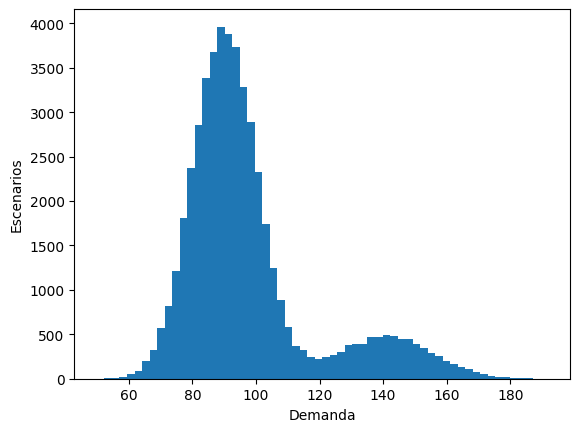

In [3]:
z,d = escenarios(SEEDS['seleccion'],50000,m)
assert len(d)==50000 and np.all(d>=0)
print('Proporción de pico simulada:',z.mean())
print(pd.DataFrame({'Z':z,'D':d}).groupby('Z').D.agg(['count','mean','std']))
plt.hist(d,bins=60);plt.xlabel('Demanda');plt.ylabel('Escenarios');plt.show()

## 3. Costo por escenario

Implementar costo, buffer usado y demanda sin atender. Probar demandas 100,125,150,151,162 para q125.

In [4]:
def costo_propio(q,d,B=25):
    # TODO: retornar costo, buffer usado y demanda sin atender.
    raise NotImplementedError('Completar ejercicio 9 antes de usar esta función')
try:
    c,b,l=costo_propio(125,[100,125,150,151,162])
    np.testing.assert_allclose(c,[2250,2250,3625,3875,6625])
    np.testing.assert_allclose(l,[0,0,0,1,12])
    print('Pruebas de costo aprobadas')
except NotImplementedError as exc:
    print('IMPLEMENTACIÓN PENDIENTE:',exc)

IMPLEMENTACIÓN PENDIENTE: Completar ejercicio 9 antes de usar esta función


## 4. Matriz y comparación de políticas

Construir matriz con las mismas demandas por columna y obtener media y frecuencia de incumplimiento.

**Bloque de referencia ejecutable:** explicar y contrastar sus resultados con tu implementación.

In [5]:
M=np.column_stack([costos(q,d,m)[0] for q in Q])
assert M.shape==(50000,11)
idx=np.r_[np.flatnonzero(z==0)[:3],np.flatnonzero(z==1)[:3]]
print(pd.DataFrame(M[idx,:],index=idx+1,columns=Q))
t=tabla(d,m)
np.testing.assert_allclose(t.media,M.mean(axis=0))
t

             100           105  ...          145          150
1    1876.312075   1890.000000  ...  2610.000000  2700.000000
2    2210.825638   2025.825638  ...  2610.000000  2700.000000
3    1800.000000   1890.000000  ...  2610.000000  2700.000000
5    6842.272629   5682.272629  ...  2610.000000  2700.000000
13  12071.064687  10911.064687  ...  3467.134231  3282.134231
28  15663.109066  14503.109066  ...  5223.109066  4072.383995

[6 rows x 11 columns]
Out[5]: 
      q        media         se  ...  wilson_sup        VaR95        CVaR95
0   100  2670.087916  10.467571  ...    0.131724  8705.452600  11105.662756
1   105  2573.513161   8.869236  ...    0.118109  7545.452600   9945.662756
2   110  2508.272428   7.351320  ...    0.101224  6385.452600   8785.662756
3   115  2468.361187   5.950022  ...    0.081093  5225.452600   7625.662756
4   120  2452.078545   4.696069  ...    0.060083  4065.452600   6465.662756
5   125  2457.562052   3.607947  ...    0.041651  3466.699572   5364.143095
6 

,q,media,se,ic_inf,ic_sup,incumplimiento,wilson_inf,wilson_sup,VaR95,CVaR95
0,100,2670.087916,10.467571,2649.571477,2690.604354,0.12876,0.125853,0.131724,8705.452600,11105.662756
1,105,2573.513161,8.869236,2556.129459,2590.896864,0.11528,0.112510,0.118109,7545.452600,9945.662756
2,110,2508.272428,7.351320,2493.863841,2522.681015,0.09858,0.095998,0.101224,6385.452600,8785.662756
3,115,2468.361187,5.950022,2456.699144,2480.023229,0.07870,0.076372,0.081093,5225.452600,7625.662756
4,120,2452.078545,4.696069,2442.874250,2461.282840,0.05800,0.055985,0.060083,4065.452600,6465.662756
5,125,2457.562052,3.607947,2450.490476,2464.633629,0.03990,0.038219,0.041651,3466.699572,5364.143095
6,130,2482.603850,2.695104,2477.321447,2487.886253,0.02510,0.023765,0.026508,3281.699572,4554.723574
7,135,2524.295422,1.954527,2520.464549,2528.126295,0.01416,0.013161,0.015234,3096.699572,3992.548756
8,140,2579.477546,1.373623,2576.785244,2582.169847,0.00758,0.006857,0.008379,2911.699572,3599.510963
9,145,2645.713512,0.940938,2643.869274,2647.557751,0.00320,0.002742,0.003735,2726.699572,3314.602212


## 5. Cola: VaR y CVaR

Ordenar costos y usar masa exacta de cola. Resolver el ejemplo de 20 costos, incluso al 92,5%.

In [6]:
def cola_propia(x,alpha=.95):
    # TODO: implementar inversa empírica y cola con masa exacta.
    raise NotImplementedError('Completar ejercicios 13 y 14')
try:
    x=np.array([100.]*18+[500.,1000.])
    np.testing.assert_allclose(cola_propia(x),[500,1000])
    assert np.isclose(cola_propia(x,.925)[1],833.3333333333333)
    print('Pruebas de cola aprobadas')
except NotImplementedError as exc:
    print('IMPLEMENTACIÓN PENDIENTE:',exc)

IMPLEMENTACIÓN PENDIENTE: Completar ejercicios 13 y 14


## 6. Selección y congelamiento

Declarar regla antes de ver holdout: media, servicio5 o servicio1. CVaR describe cola y no es un coeficiente añadido al objetivo.

**Bloque de referencia ejecutable:** explicar y contrastar sus resultados con tu implementación.

In [7]:
frozen=dict(media=seleccionar(t),servicio5=seleccionar(t,.05),servicio1=seleccionar(t,.01))
assert frozen==dict(media=120,servicio5=125,servicio1=140)
assert seleccionar(t,0.) is None
print('Políticas congeladas antes de holdout:',frozen)
print('Regla Wilson superior:',seleccionar(t,.05,True),seleccionar(t,.01,True))
print('Comparación pareada:',diferencia(d,125,120,m))

Políticas congeladas antes de holdout: {'media': 120, 'servicio5': 125, 'servicio1': 140}
Regla Wilson superior: 125 140
Comparación pareada: {'qa': 125, 'qb': 120, 'media': np.float64(5.483507587805635), 'se': np.float64(1.2037812133984447), 'ic_inf': np.float64(3.1240964095446833), 'ic_sup': np.float64(7.842918766066586)}


## 7. Holdout independiente

Evaluar solo políticas congeladas. No seleccionar dentro de holdout.

**Bloque de referencia ejecutable:** explicar y contrastar sus resultados con tu implementación.

In [8]:
zh,dh=escenarios(SEEDS['holdout'],50000,m)
hold=tabla(dh,m,sorted(set(frozen.values())))
assert set(hold.q)==set(frozen.values())
assert not np.array_equal(d,dh)
print(hold.to_string(index=False))
print('Diferencia pareada holdout:',diferencia(dh,125,120,m))
ref=pd.read_csv(ROOT/'results/holdout.csv')
np.testing.assert_allclose(hold.select_dtypes('number'),ref.select_dtypes('number'),rtol=1e-10)

  q       media       se      ic_inf      ic_sup  incumplimiento  wilson_inf  wilson_sup       VaR95      CVaR95
120 2441.349869 4.630478 2432.274132 2450.425605         0.05506    0.053095    0.057094 3911.986187 6372.983965
125 2449.593629 3.568275 2442.599810 2456.587448         0.03808    0.036438    0.039793 3432.936961 5294.402820
140 2577.330673 1.395902 2574.594704 2580.066641         0.00684    0.006154    0.007601 2877.936961 3581.007012
Diferencia pareada holdout: {'qa': 125, 'qb': 120, 'media': np.float64(8.243759961154772), 'se': np.float64(1.1813316982022166), 'ic_inf': np.float64(5.928349832678428), 'ic_sup': np.float64(10.559170089631117)}


## 8. Estrés y sensibilidad

Mantener q125 al estresar. Luego reseleccionar solo como diagnóstico, con nueva validación si se decide adoptar otro q.

**Bloque de referencia ejecutable:** explicar y contrastar sus resultados con tu implementación.

In [9]:
casos={'base':m,'pico_25':replace(m,p=.25),'pico_intenso':replace(m,mu1=155,sd1=20),'buffer_10':replace(m,B=10),'penalidad_350':replace(m,penalidad=350)}
filas=[]
for nombre,ms in casos.items():
    _,ds=escenarios(SEEDS['estres'],50000,ms)
    ts=tabla(ds,ms)
    fila=ts[ts.q==125].iloc[0].to_dict();fila['caso']=nombre
    fila['q_reseleccion_diagnostica']=seleccionar(ts,.05)
    filas.append(fila)
estres=pd.DataFrame(filas)
print(estres[['caso','media','incumplimiento','CVaR95','q_reseleccion_diagnostica']].to_string(index=False))
assert np.isclose(estres.iloc[0].incumplimiento,estres.iloc[-1].incumplimiento)
assert estres.iloc[1].incumplimiento>.05

         caso       media  incumplimiento       CVaR95  q_reseleccion_diagnostica
         base 2448.363927         0.03730  5298.274785                        125
      pico_25 2582.581900         0.06336  6377.668645                        130
 pico_intenso 2807.767152         0.08812 10310.494299                        140
    buffer_10 2636.124827         0.09322  8126.620724                        140
penalidad_350 2482.374651         0.03730  5978.489259                        125


## 9. Recomendación y límites

Escribir 250–350 palabras: criterio, costo de protección, evidencia, estrés, validación real y estado temporal. Identificar quién conoce qué antes de elegir q.

In [10]:
recomendacion = ''  # TODO: escribir recomendación propia y condiciones.
print('RECOMENDACIÓN PENDIENTE' if not recomendacion.strip() else recomendacion)

RECOMENDACIÓN PENDIENTE


## 10. Persistencia y Markov

Verificar que P conserva 15% en estacionariedad. La matriz es una hipótesis didáctica, no una estimación del CSV.

**Bloque de referencia ejecutable:** explicar y contrastar sus resultados con tu implementación.

In [11]:
pi=np.array([.85,.15])
np.testing.assert_allclose(P.sum(axis=1),[1,1])
np.testing.assert_allclose(pi@P,pi)
print('Duración pico iid:',1/.85,'persistente:',1/.34)
filas=[]
for nombre,persistente in [('iid',False),('persistente',True)]:
    zp,dp=trayectorias(persistente=persistente,m=m)
    cp,bp,lp=costos(125,dp,m);total=cp.sum(axis=1)
    filas.append(dict(modelo=nombre,media_total=total.mean(),se=total.std(ddof=1)/np.sqrt(len(total)),CVaR95_total=cola(total)[1],p_racha_inc=racha3(lp>0).mean(),p_pico=zp.mean()))
markov=pd.DataFrame(filas)
print(markov.to_string(index=False))
print('Media teórica en ambos modelos:',30*esperado(125,m))
assert markov.iloc[1].CVaR95_total>markov.iloc[0].CVaR95_total
assert markov.iloc[1].p_racha_inc>markov.iloc[0].p_racha_inc
assert np.all(np.abs(markov.media_total-30*esperado(125,m))<4*markov.se)

Duración pico iid: 1.1764705882352942 persistente: 2.941176470588235
     modelo  media_total        se  CVaR95_total  p_racha_inc   p_pico
        iid 73454.155792 60.408913  84494.965773       0.0014 0.148833
persistente 73350.104651 85.189030  90045.234629       0.0230 0.146467
Media teórica en ambos modelos: 73511.74124292622


## Entrega

Adjuntar funciones propias, pruebas, tabla de evidencia y recomendación. Explicar qué cambia si el holdout modifica la decisión y por qué las ventanas de una trayectoria persistente no son réplicas independientes.